In [2]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt

In [3]:
data = pd.read_csv("planets_300.csv")
x = np.log(data[["a_AU", "M_star_solar"]])
y = np.log(data["T_years"])

In [4]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=0) # wont change the predictions everytime


In [5]:
model = LinearRegression()
model.fit(x_train, y_train)

LinearRegression()

In [6]:
y_predicted = model.predict(x_test)

In [7]:
baseline = np.full(len(y_test), np.mean(y_train))

In [8]:
rmse = lambda p: np.sqrt(mean_squared_error(y_test, p))

In [9]:
rmse_m = rmse(y_predicted)
rmse_b = rmse(baseline)
r_score = r2_score(y_test, y_predicted)

In [10]:
print("  coef (log a, log M):", model.coef_, " intercept:", model.intercept_)
print("  model RMSE:", rmse(y_predicted), " baseline RMSE:", rmse(baseline))
print("  model R2:", r2_score(y_test, y_predicted))

  coef (log a, log M): [ 1.5006282  -0.50501103]  intercept: -0.004534282861803796
  model RMSE: 0.03209486900630599  baseline RMSE: 1.3557607816273396
  model R2: 0.9994384950780175


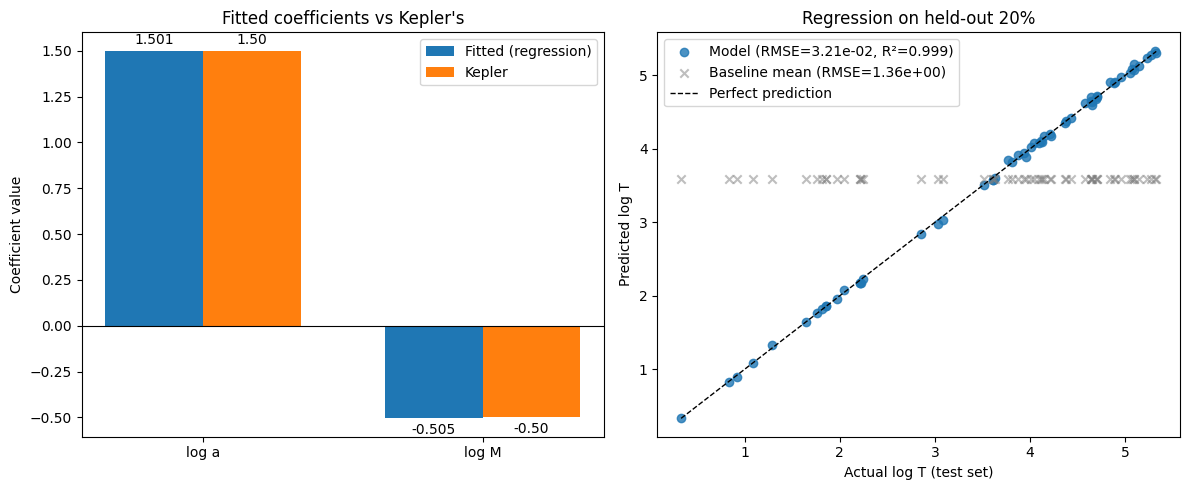

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
kepler = 1.5, -0.5


ax = axes[0]
labels = ["log a", "log M"]
x = np.arange(len(labels))
w = 0.35
b1 = ax.bar(x - w/2, model.coef_, w, label="Fitted (regression)", color="tab:blue")
b2 = ax.bar(x + w/2, kepler, w, label="Kepler", color="tab:orange")
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel("Coefficient value")
ax.set_title("Fitted coefficients vs Kepler's")
ax.bar_label(b1, fmt="%.3f", padding=3)
ax.bar_label(b2, fmt="%.2f", padding=3)
ax.legend()


ax = axes[1]
ax.scatter(y_test, y_predicted, label=f"Model (RMSE={rmse_m:.2e}, R²={r_score:.3f})",
           color="tab:blue", alpha=0.8)
ax.scatter(y_test, baseline, label=f"Baseline mean (RMSE={rmse_b:.2e})",
           color="tab:gray", alpha=0.5, marker="x")
lo, hi = y_test.min(), y_test.max()
ax.plot([lo, hi], [lo, hi], "k--", lw=1, label="Perfect prediction")
ax.set_xlabel("Actual log T (test set)")
ax.set_ylabel("Predicted log T")
ax.set_title("Regression on held-out 20%")
ax.legend()

plt.tight_layout()
plt.savefig("part3_results.png", dpi=150)
plt.show()